# A machine learning approach to volatility forecasting: replication and extension to 2016–2026

**Paper:** Christensen, Siggaard & Veliyev, *A machine learning approach to volatility forecasting*, Journal of Financial Econometrics (arXiv:2601.13014). Original sample: 29 DJIA stocks, 2001–2017.

**Our question.** Does the paper's result (off-the-shelf ML beats the HAR family, more so with extra predictors and at longer horizons) hold out-of-sample in a new regime (2016–2026) with open data?

**Hypotheses.** H1: with RV lags only (M_HAR) ML ≈ HAR. H2: with extra predictors (M_ALL) ML beats HAR. H3: the ML edge grows with the horizon (1 day → 1 week → 1 month).

**Data.** 5-minute realized measures for the Dow 30 from **VOLARE** (Cipollini et al. 2026, arXiv:2602.19732; cleaned tick data), 30-day ATM implied volatility per stock from **LSEG Workspace**, macro series from FRED, the Philadelphia Fed and Yahoo Finance.

**Three sample splits** (the paper itself shows that results depend on whether a crisis is in the training or the test sample, Appendix A.1):

| Scenario | Training | Validation | Test | COVID (2020) is … |
|---|---|---|---|---|
| **Baseline** | 70% (2016–2023) | 10% | 20% (2024–2026) | in the training sample |
| **COVID in test** | 2016 – Jun 2019 | Jul – Dec 2019 | 2020 – 2026 | out-of-sample (as in the paper's 1,000-day robustness check) |
| **Without 2020** | as baseline | as baseline | as baseline | removed from every estimation window |

All code is in `volml.py` (models, evaluation) and `volplots.py` (figures). Figures for the slides are written to `results/<run>/slides/`, tables to `results/<run>/slides_tables.xlsx`.

In [1]:
# !pip install pandas numpy scipy scikit-learn matplotlib joblib openpyxl yfinance pyarrow
import os, time, copy
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import volml as V, volplots as P

QUICK = False       # True: 8 stocks + lighter models for a quick check
DRY_RUN = False     # True: simulated data (pipeline test only, no downloads)

# Data source: "volare" (main) | "alpaca" (5-min bars, robustness) | "yahoo" | "binance"
DATA_SOURCE = "volare"
PATHS = {"volare": "data/volare", "alpaca": "data/alpaca/realized.csv",
         "yahoo": "data/yahoo/realized.csv", "binance": "data/binance/realized.csv"}

cfg = V.Config(volare_path=PATHS[DATA_SOURCE])
cfg.start = "2016-01-01"                                  # common start for all sources and the LSEG IV
cfg.iv_file = "data/lseg/iv.csv" if os.path.exists("data/lseg/iv.csv") else None
if QUICK and DATA_SOURCE != "binance":
    cfg.symbols = ["AAPL", "MSFT", "JPM", "KO", "BA", "CVX", "WMT", "IBM"]
    cfg.rf_trees, cfg.nn_seeds, cfg.nn_top, cfg.refit_trees = 200, 5, 3, 126

# The three split scenarios (see table above). Remove names from RUN to skip a scenario.
SCENARIOS = {
    "baseline":   dict(label="Baseline",      split=None,                         train_exclude=None),
    "covid_test": dict(label="COVID in test", split=("2019-06-28", "2019-12-31"), train_exclude=None),
    "ex2020":     dict(label="Without 2020",  split=None,                         train_exclude=("2020-01-01", "2020-12-31")),
}
RUN = ["baseline", "covid_test", "ex2020"]

EVENTS = {"COVID": ("2020-02-20", "2020-05-29"), "2022 bear market": ("2022-01-03", "2022-12-30"),
          "Tariff shock": ("2025-04-01", "2025-04-30")}
TARIFF = EVENTS["Tariff shock"]
P.setup_style()
cfg

Config(volare_path='data/volare', symbols=['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT'], start='2016-01-01', end=None, horizons=(1, 5, 22), datasets=('M_HAR', 'M_ALL'), train_frac=0.7, val_frac=0.1, split=None, train_exclude=None, refit_linear=1, refit_reg=22, refit_trees=63, models=('HAR', 'HAR-X', 'LogHAR', 'LevHAR', 'SHAR', 'HARQ', 'RR', 'LA', 'EN', 'RF', 'GB', 'NN'), rf_trees=500, rf_min_leaf=5, nn_archs=((4, 2),), nn_seeds=10, nn_top=5, nn_max_epochs=500, nn_patience=50, nn_lr=0.001, nn_l2=0.0001, nn_batch=32, n_jobs=-1, cache_dir='data/cache', results_dir='results', offline_macro=False, ea_file=None, iv_file='data/lseg/iv.csv', seed=42)

## 1. Data

VOLARE: `data/volare/realized_variance_stocks.csv` (the loader uses `rv5`, `rq5`, `rsp5`, `rsn5`, `open_price`, `close_price`, `volume`). LSEG IV: `data/lseg/iv.csv` (from `lseg/LSEG_IV_Download.xlsx` → `python lseg/convert_lseg_excel.py …`). Macro series are downloaded once and cached in `data/cache/`.

In [2]:
if DRY_RUN:
    panel, macro = V.simulate_panel(n_stocks=6, n_days=2800)
    panel = panel.rename(columns={"rv5": "rv", "rq5": "rq", "rsp5": "rsp", "rsn5": "rsn"})
    panel[["rv", "rsp", "rsn"]] *= 1e4; panel["rq"] *= 1e8
    cfg.symbols = sorted(panel.symbol.unique())
else:
    panel = V.load_volare(cfg.volare_path, symbols=None if DATA_SOURCE == "binance" else cfg.symbols)
    if DATA_SOURCE == "binance":
        cfg.symbols = sorted(panel.symbol.unique())
    macro = V.load_macro(cfg)
panel = panel[panel["date"] >= cfg.start].reset_index(drop=True)

ea = pd.read_csv(cfg.ea_file, parse_dates=["date"]) if cfg.ea_file else None
iv = pd.read_csv(cfg.iv_file, parse_dates=["date"]) if cfg.iv_file else None
print("implied vol:", "none" if iv is None else f"{iv.symbol.nunique()} stocks, {iv.date.min().date()} -> {iv.date.max().date()}")
TAG = f"{DATA_SOURCE}_{'quick' if QUICK else 'full'}{'_iv' if iv is not None else ''}"
OUT = os.path.join("results", TAG); FIG = os.path.join(OUT, "slides"); os.makedirs(FIG, exist_ok=True)
TABLES = {}                                   # everything collected here is exported to Excel at the end
panel.groupby("symbol")["date"].agg(["min", "max", "count"]).T

VOLARE: 30 symbols, 2015-01-02 -> 2026-09-30, columns: ['date', 'symbol', 'rv', 'rq', 'rsp', 'rsn', 'open', 'close', 'volume']
macro VIX: 1990-01-02 -> 2026-10-15
macro EPU: 1985-01-01 -> 2026-10-15
macro US3M: 1954-01-04 -> 2026-10-15
macro HSI: 2014-01-03 -> 2026-10-16
macro ADS: 1960-03-01 -> 2026-10-10
implied vol: 28 stocks, 2015-12-31 -> 2026-10-16


symbol,AAPL,AMGN,AMZN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,...,MSFT,NKE,NVDA,PG,SHW,TRV,UNH,V,VZ,WMT
min,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,...,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00,2016-01-04 00:00:00
max,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,...,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00,2026-09-30 00:00:00
count,2701,2701,2701,2701,2701,2701,2701,2701,2701,2701,...,2701,2701,2701,2701,2701,2701,2701,2701,2701,2701


### Table 1 — descriptive statistics (realized volatility annualized in %)

In [3]:
ann = lambda x: np.sqrt(252 * x)
desc = []
for s, g in panel.groupby("symbol"):
    f = V.build_features(g, macro, cfg, None, None if iv is None else iv[iv.symbol == s])
    t = pd.DataFrame({"RVD": ann(f["RVD"]), "RVW": ann(f["RVW"]), "RVM": ann(f["RVM"])})
    for c in V.extra_cols(f):
        t[c] = f[c]
    desc.append(t.describe().T.assign(skew=t.skew(), kurt=t.kurt() + 3))
desc = pd.concat(desc).groupby(level=0).mean()[["mean", "50%", "max", "min", "std", "skew", "kurt"]].round(2)
TABLES["T1_descriptives"] = desc
desc

,mean,50%,max,min,std,skew,kurt
ADS,-0.22,-0.13,9.64,-26.64,2.77,-5.97,56.09
DVOL,0.00,-0.01,1.94,-1.56,0.35,0.27,5.07
EPU,175.79,126.30,1026.38,4.05,139.46,1.85,7.04
HSI,1.89,0.56,201.16,0.00,5.70,19.79,603.86
IV,25.33,23.84,104.11,11.76,8.19,2.62,22.09
M1W,0.08,0.14,16.61,-15.92,2.90,-0.09,6.13
RVD,19.90,17.60,158.33,5.71,10.74,4.52,42.11
RVM,20.92,19.19,85.40,9.86,8.55,3.73,26.41
RVW,20.46,18.44,120.65,8.02,9.63,4.33,37.06
US3M,-0.00,0.00,0.17,-0.22,0.02,-1.52,20.64


Baseline       train <= 2023-07-18  val <= 2024-08-09  test after
COVID in test  train <= 2019-06-28  val <= 2019-12-31  test after
Without 2020   train <= 2023-07-18  val <= 2024-08-09  test after   (removed: ('2020-01-01', '2020-12-31'))


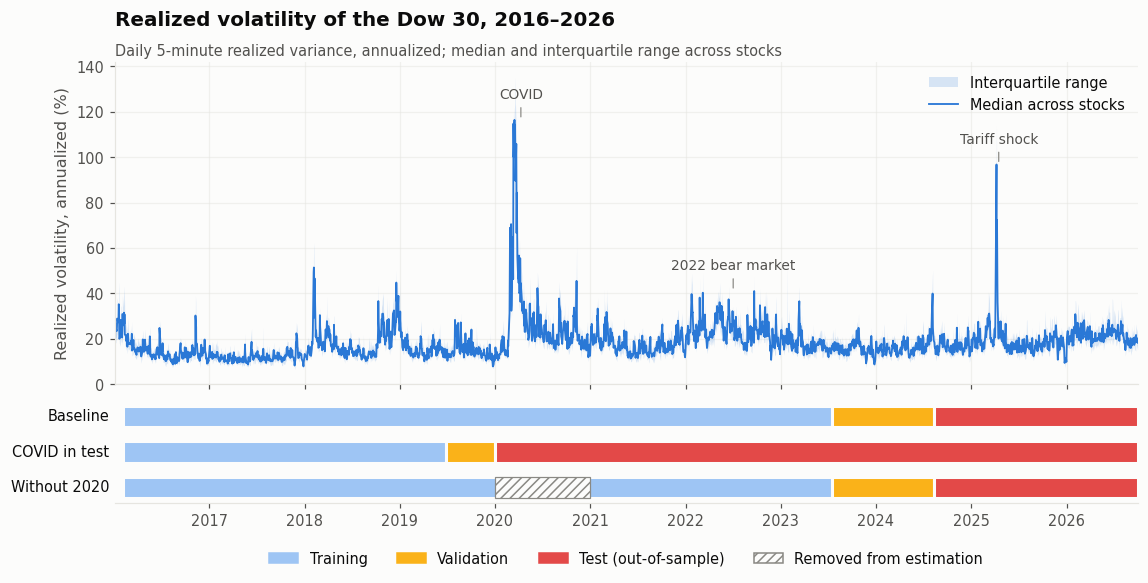

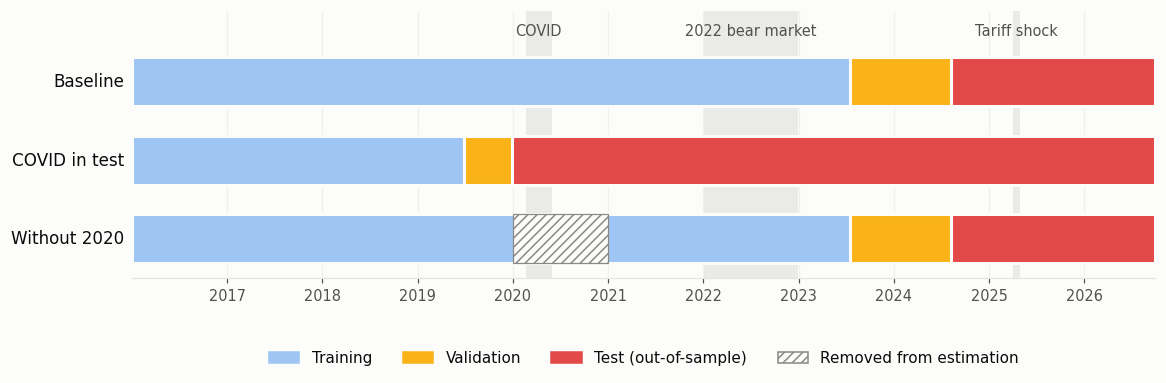

In [4]:
def scenario_cfg(name):
    c = copy.deepcopy(cfg)
    c.split, c.train_exclude = SCENARIOS[name]["split"], SCENARIOS[name]["train_exclude"]
    return c

SPLITS = {}
for name in SCENARIOS:
    d_tr, d_va = V.split_dates(panel, scenario_cfg(name))
    SPLITS[SCENARIOS[name]["label"]] = (d_tr, d_va, SCENARIOS[name]["train_exclude"])
    print(f"{SCENARIOS[name]['label']:14s} train <= {d_tr.date()}  val <= {d_va.date()}  test after"
          + (f"   (removed: {SCENARIOS[name]['train_exclude']})" if SCENARIOS[name]["train_exclude"] else ""))
P.fig_rv_timeline(panel, SPLITS, EVENTS, save=f"{FIG}/01_rv_timeline_splits.png"); plt.show()
P.fig_splits(SPLITS, panel["date"].min(), panel["date"].max(), EVENTS, save=f"{FIG}/02_splits.png"); plt.show()

## 2. Forecasting

Rolling out-of-sample forecasts for every model, both information sets and h = 1, 5, 22, for each scenario. Each run is cached in `results/<run>/<scenario>/preds.pkl`; re-running the notebook only computes what is missing. On a 12-core laptop roughly: baseline ≈ 25 min, without 2020 ≈ 25 min, COVID in test ≈ 35–45 min (longer test period, shorter training windows).

In [5]:
def run_scenario(name):
    c = scenario_cfg(name)
    path = os.path.join(OUT, name, "preds.pkl")
    if os.path.exists(path):
        return pd.read_pickle(path)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    t0 = time.time()
    res = V.run_all(c, panel, macro, ea, iv)
    pd.to_pickle(res, path)
    print(f"{name}: done in {(time.time() - t0) / 60:.1f} min")
    return res

RESULTS, INFO = {}, {}
for name in RUN:
    RESULTS[name], INFO[name] = run_scenario(name)
    s0 = next(iter(INFO[name]))
    print(f"{SCENARIOS[name]['label']:14s}", INFO[name][s0][("M_HAR", 1)]["n"])
preds = RESULTS["baseline"]                    # sections 3-5 use the baseline split

Baseline       {'train': 1876, 'val': 268, 'test': 535, 'test_start': '2024-08-12', 'test_end': '2026-09-29'}
COVID in test  {'train': 857, 'val': 128, 'test': 1694, 'test_start': '2020-01-02', 'test_end': '2026-09-29'}
Without 2020   {'train': 1623, 'val': 268, 'test': 535, 'test_start': '2024-08-12', 'test_end': '2026-09-29'}


## 3. Main result (baseline split): replication vs. the paper

Entries: cross-sectional average of MSE(model)/MSE(HAR); below 1 = beats the HAR. Stars: one-sided Diebold–Mariano test rejected for more than half of the stocks at 10% (\*), 5% (\*\*), 1% (\*\*\*), as in the paper's Tables 2–7.

In [6]:
summary = {}
for ds in cfg.datasets:
    for h in cfg.horizons:
        summary[(ds, f"h={h}", "ours")] = V.vs_benchmark(preds, ds, h)["txt"]
        summary[(ds, f"h={h}", "paper")] = pd.Series(V.PAPER[(ds, h)]).map("{:.3f}".format)
summary = pd.DataFrame(summary).reindex(P.ORDER).fillna("")
summary.index = [P.NAME[m] for m in summary.index]
TABLES["T2_vs_paper_baseline"] = summary
summary

M_HAR                                         M_ALL  \
                         h=1            h=5           h=22             h=1   
                        ours  paper    ours  paper    ours  paper     ours   
HAR-X                                                               0.929*   
LogHAR                 0.921  0.995  0.823*  1.091  0.842*  1.052  0.854**   
LevHAR                 1.003  1.073   1.023  1.089   1.027  1.030    0.935   
SHAR                   1.042  1.009   1.098  0.937   1.083  1.034    0.954   
HARQ                   1.032  1.059   1.169  1.043   1.254  0.994    0.946   
Ridge                  0.951  1.000  0.864*  1.019   0.935  1.100    0.908   
Lasso                  0.971  1.003   0.913  1.024   0.991  1.107  0.923**   
Elastic net            0.954  0.999  0.867*  1.019   0.944  1.111  0.894**   
Random forest          1.010  1.020   1.247  0.959   2.241  1.019  0.868**   
Gradient boosting      1.238  1.054   1.844  1.164   2.760  1.219    0.957   
Neural net (single)    1.029  0.966   0.991  0.947   1.160  0.989    1.000   
Neural net (ensemble)  0.965  0.958   0.914  0.937   1.098  0.958   0.915*   

                                                           
                                 h=5          h=22         
                       paper    ours  paper   ours  paper  
HAR-X                  0.966   0.987  1.037  1.296  1.290  
LogHAR                 0.901  0.746*  0.970  0.832  0.919  
LevHAR                 1.003   1.000  1.076  1.328  1.328  
SHAR                   1.080   1.035  0.913  1.307  1.312  
HARQ                   1.289   1.050  1.459  1.311  1.569  
Ridge                  0.919  0.784*  0.954  0.897  1.111  
Lasso                  0.936  0.821*  0.958  0.886  1.378  
Elastic net            0.916  0.778*  0.925  0.876  1.107  
Random forest          0.901  0.898*  0.796  1.148  0.604  
Gradient boosting      0.962   1.924  0.930  0.904  0.829  
Neural net (single)    0.893   0.938  0.865  1.247  0.816  
Neural net (ensemble)  0.885  0.809*  0.846  0.932  0.786

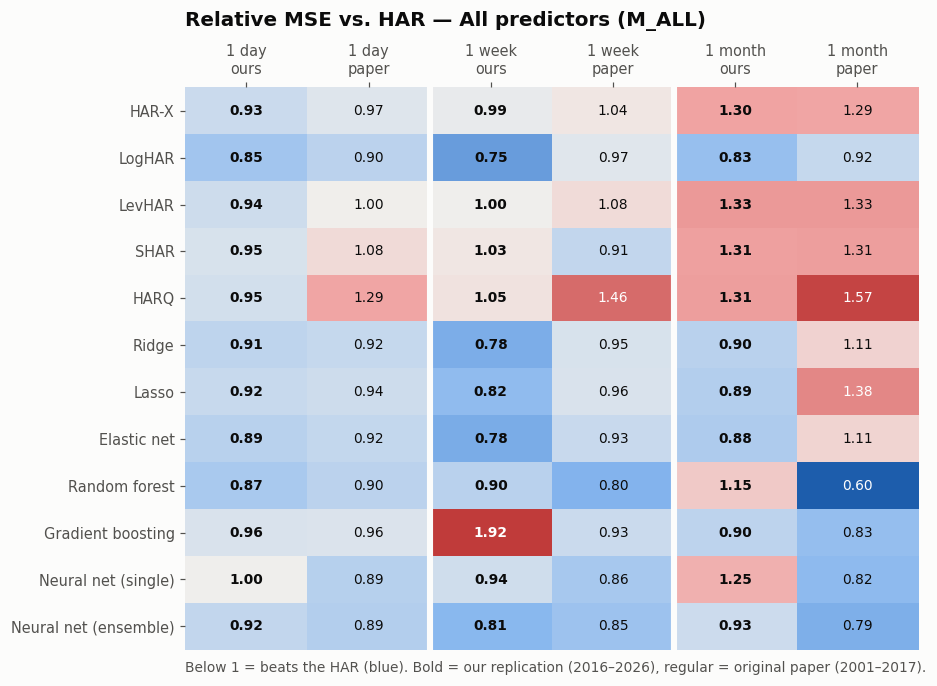

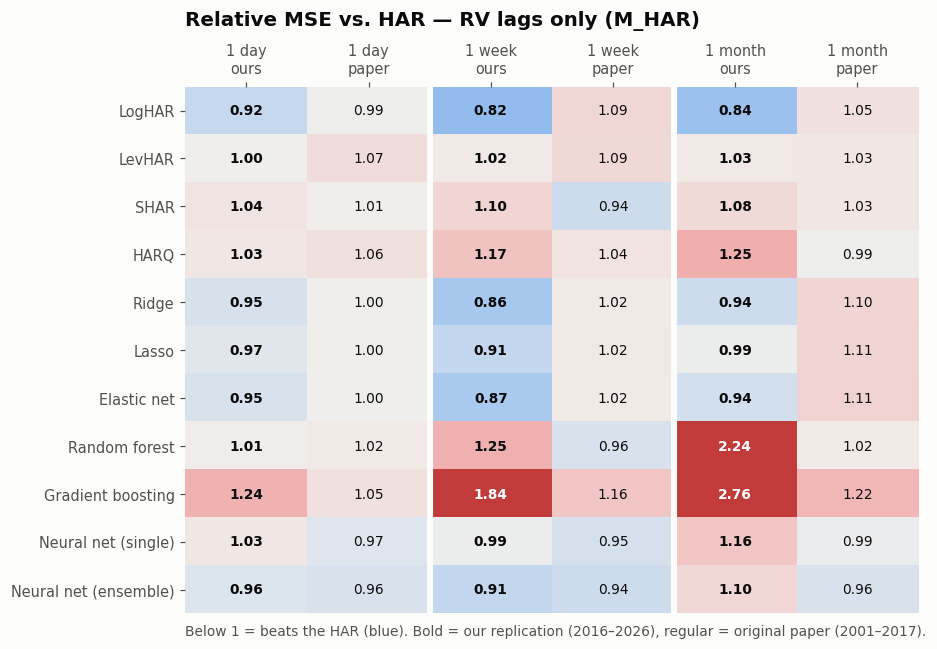

In [7]:
P.fig_heatmap_vs_paper(preds, "M_ALL", save=f"{FIG}/02_heatmap_vs_paper_M_ALL.png"); plt.show()
P.fig_heatmap_vs_paper(preds, "M_HAR", save=f"{FIG}/03_heatmap_vs_paper_M_HAR.png"); plt.show()

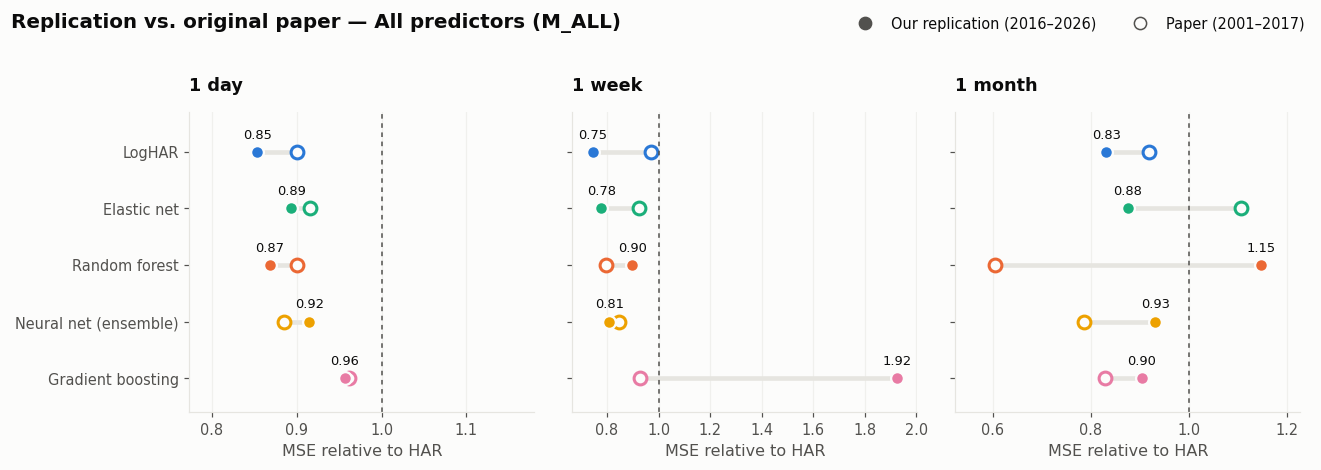

In [8]:
P.fig_dumbbell(preds, "M_ALL", save=f"{FIG}/04_dumbbell_vs_paper_M_ALL.png"); plt.show()

Full pairwise matrix in the paper's layout (row = benchmark, column = model), $\mathcal M_{ALL}$, 1 day:

In [9]:
pairwise = V.relative_table(preds, "M_ALL", 1)[1]
TABLES["T3_pairwise_M_ALL_h1"] = pairwise
pairwise

,HAR,HAR-X,LogHAR,LevHAR,SHAR,HARQ,RR,LA,EN,RF,GB,NN2_1,NN2_ens
HAR,-,0.929*,0.854**,0.935,0.954,0.946,0.908,0.923**,0.894**,0.868**,0.957,1.000,0.915*
HAR-X,1.084,-,0.923,1.007,1.027,1.018,0.982,0.998,0.967,0.938,1.024,1.084,0.989
LogHAR,1.179,1.091,-,1.098,1.122,1.112,1.066,1.085,1.050,1.019,1.117,1.175,1.073
LevHAR,1.078,0.994,0.917,-,1.021,1.012,0.976,0.993,0.961,0.933,1.019,1.079,0.985
SHAR,1.058,0.976,0.901*,0.982,-,0.993,0.958,0.975,0.944,0.916,1.001,1.060,0.967
HARQ,1.069,0.985,0.910,0.992,1.011,-,0.968,0.985,0.954,0.925,1.005,1.072,0.977
RR,1.106,1.024,0.940*,1.030,1.052,1.043,-,1.018,0.985,0.958,1.052,1.101,1.008
LA,1.087,1.007,0.925**,1.014,1.035,1.027,0.985,-,0.969,0.941,1.035,1.084,0.992
EN,1.123,1.041,0.955*,1.048,1.069,1.061,1.016,1.033,-,0.972,1.067,1.118,1.023
RF,1.161,1.075,0.987,1.083,1.105,1.094,1.052,1.069,1.034,-,1.088,1.157,1.056


### Robustness: QLIKE loss and win rates

M_HAR                    M_ALL                 
            h=1     h=5   h=22       h=1       h=5   h=22
HAR-X                              4.406     4.595  4.011
LogHAR   0.963*  0.927*  0.904  0.874***  0.821***  0.922
LevHAR    1.216   1.234  1.068     5.060     7.473  8.687
SHAR      1.061   1.039  1.016   192.823     5.749  3.307
HARQ      1.122   1.162  1.107     2.475     2.382  2.240
RR        0.984   0.953  1.016     1.094     0.891  1.062
LA        1.005   0.998  1.033    1.015*    0.891*  0.999
EN        0.988   0.958  1.019     0.959     0.861  0.991
RF        1.012   1.034  1.160   0.897**    0.884*  1.029
GB        1.014   1.042  1.116    0.966*     0.925  1.136
NN2_1     1.104   1.317  1.981     1.406     1.686  2.214
NN2_ens   1.027   1.250  1.790     1.105     1.009  1.464

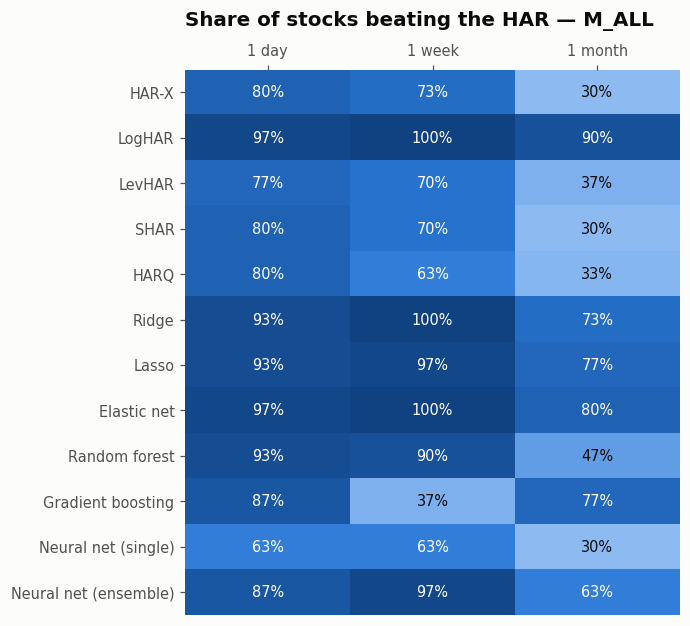

In [10]:
ql = pd.DataFrame({(ds, f"h={h}"): V.vs_benchmark(preds, ds, h, loss="qlike")["txt"]
                   for ds in cfg.datasets for h in cfg.horizons}).reindex(P.ORDER).fillna("")
TABLES["T4_qlike_baseline"] = ql
display(ql)
P.fig_winrate(preds, "M_ALL", save=f"{FIG}/05_winrate_M_ALL.png"); plt.show()

## 4. Where do the gains come from?

MSE on realized variance in levels is dominated by a few extreme days. The figures below show how much of the result is driven by the tariff shock in April 2025.

h= 1: 54% of the HAR's squared error comes from 4% of test days (Apr 2025)
h= 5: 56% of the HAR's squared error comes from 4% of test days (Apr 2025)
h=22: 26% of the HAR's squared error comes from 4% of test days (Apr 2025)


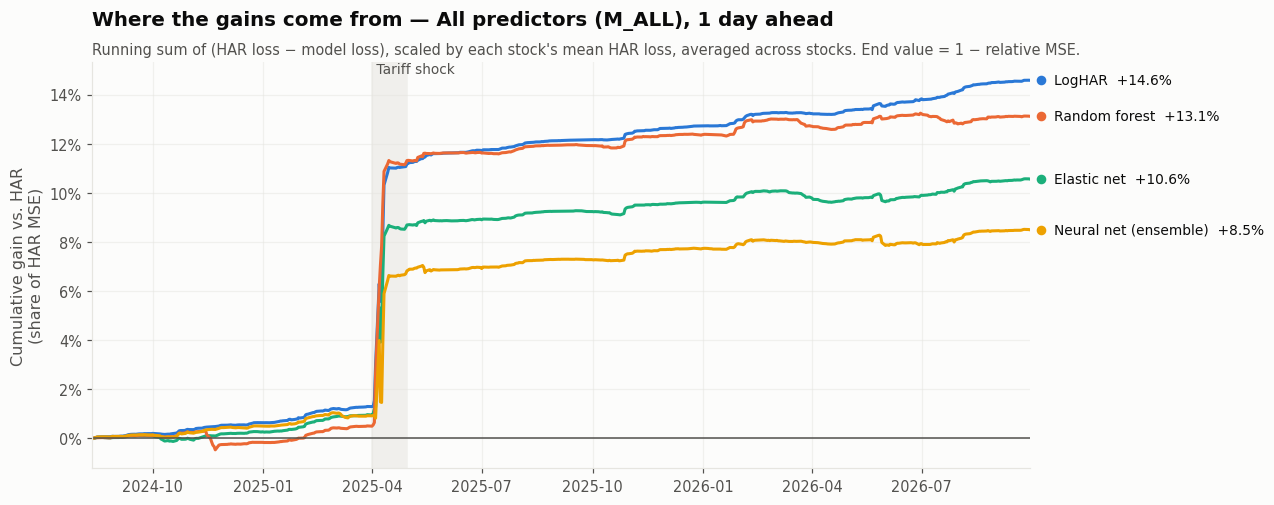

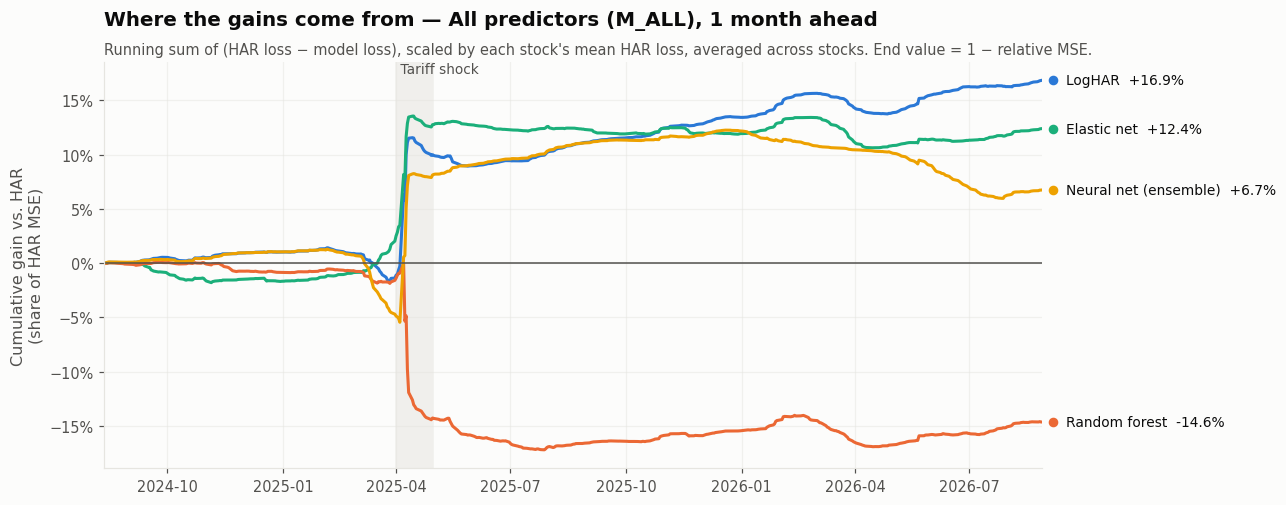

In [11]:
for h in cfg.horizons:
    share, frac = V.error_share(preds, TARIFF, "M_HAR", h)
    print(f"h={h:2d}: {share:.0%} of the HAR's squared error comes from {frac:.0%} of test days (Apr 2025)")
P.fig_cumgain(preds, "M_ALL", 1, events=EVENTS, save=f"{FIG}/06_cumulative_gain_M_ALL_h1.png"); plt.show()
P.fig_cumgain(preds, "M_ALL", 22, events=EVENTS, save=f"{FIG}/07_cumulative_gain_M_ALL_h22.png"); plt.show()

In [12]:
ex = {}
for ds in cfg.datasets:
    for h in cfg.horizons:
        ex[(ds, f"h={h}", "all")] = V.vs_benchmark(preds, ds, h)["txt"]
        ex[(ds, f"h={h}", "ex Apr 2025")] = V.vs_benchmark(preds, ds, h, exclude=("2025-03-01", "2025-04-30"))["txt"]
ex = pd.DataFrame(ex).reindex(P.ORDER).fillna("")
TABLES["T5_ex_tariff_shock"] = ex
ex

M_HAR                                                        M_ALL  \
           h=1                 h=5                h=22                  h=1   
           all ex Apr 2025     all ex Apr 2025     all ex Apr 2025      all   
HAR-X                                                                0.929*   
LogHAR   0.921    0.938***  0.823*     0.798**  0.842*       0.904  0.854**   
LevHAR   1.003       1.111   1.023       1.151   1.027       1.192    0.935   
SHAR     1.042       1.081   1.098       1.157   1.083       1.092    0.954   
HARQ     1.032       1.119   1.169       1.356   1.254       1.444    0.946   
RR       0.951     0.954**  0.864*     0.854**   0.935       1.046    0.908   
LA       0.971     0.977**   0.913       0.940   0.991       1.087  0.923**   
EN       0.954     0.958**  0.867*     0.860**   0.944       1.053  0.894**   
RF       1.010       1.028   1.247       1.005   2.241       1.698  0.868**   
GB       1.238       1.100   1.844       1.028   2.760       1.394    0.957   
NN2_1    1.029       1.007   0.991       0.968   1.160       1.383    1.000   
NN2_ens  0.965       0.967   0.914       0.896   1.098       1.289   0.915*   

                                                            
                        h=5               h=22              
        ex Apr 2025     all ex Apr 2025    all ex Apr 2025  
HAR-X         1.090   0.987       1.315  1.296       1.920  
LogHAR     0.892***  0.746*     0.692**  0.832       0.847  
LevHAR        1.138   1.000       1.355  1.328       1.987  
SHAR          1.124   1.035       1.358  1.307       1.918  
HARQ          1.117   1.050       1.386  1.311       1.920  
RR            0.967  0.784*      0.853*  0.897       1.163  
LA          0.958**  0.821*       0.894  0.886       1.141  
EN          0.940**  0.778*       0.816  0.876       1.111  
RF           0.955*  0.898*     0.842**  1.148       1.177  
GB           1.070*   1.924      1.735*  0.904       1.069  
NN2_1         0.996   0.938      0.935*  1.247       1.497  
NN2_ens     0.938**  0.809*     0.764**  0.932       1.109

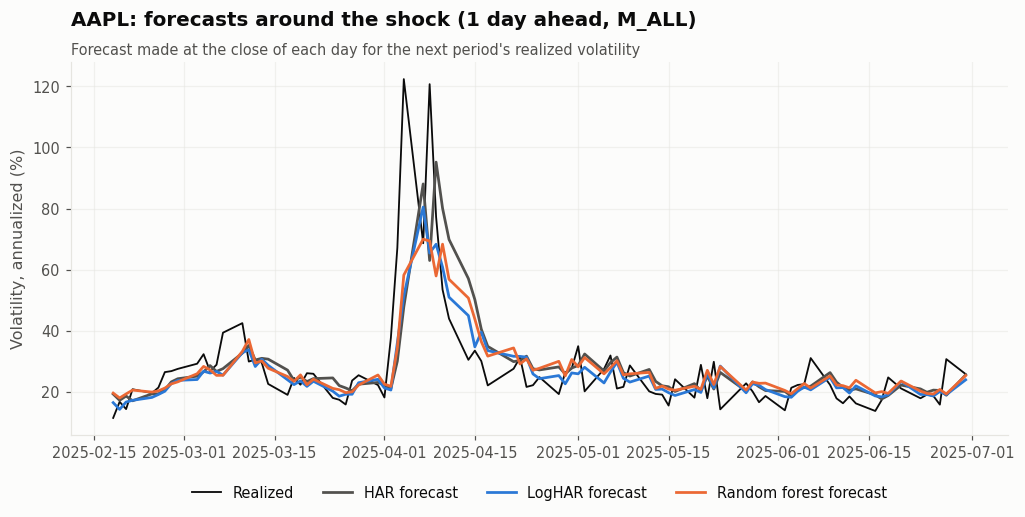

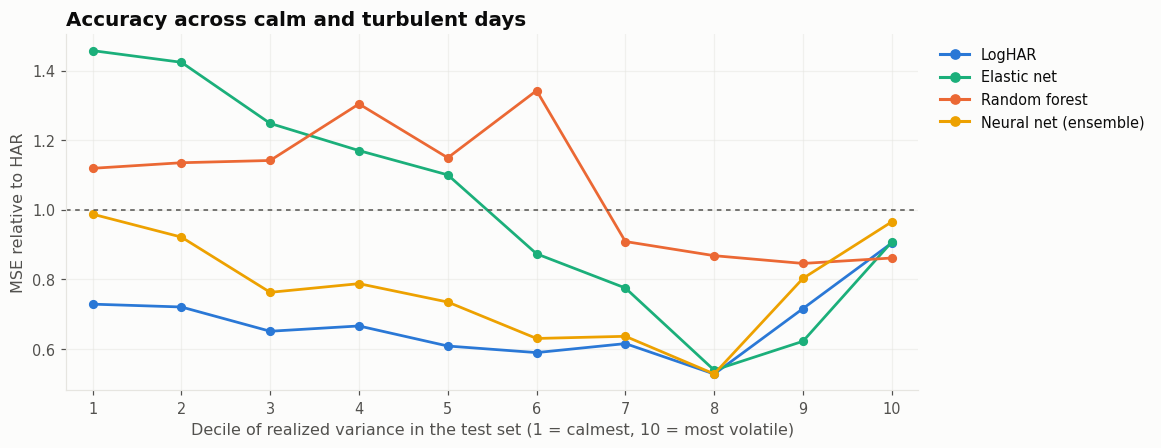

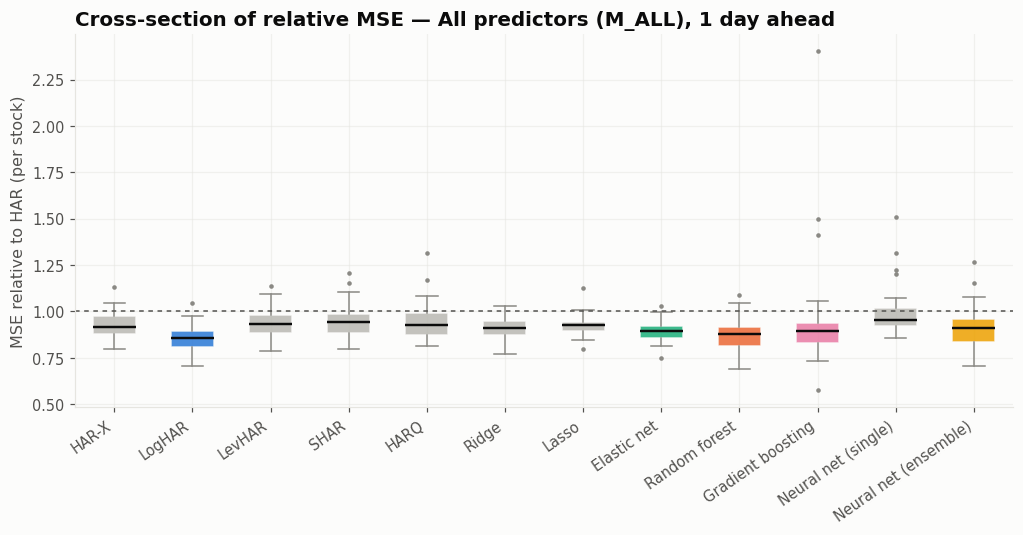

In [13]:
P.fig_forecast_zoom(preds, "AAPL" if "AAPL" in preds else next(iter(preds)), "M_ALL", 1, ["HAR", "LogHAR", "RF"],
                    "2025-02-15", "2025-06-30", save=f"{FIG}/08_forecast_zoom_tariff.png"); plt.show()
dec = V.decile_table(preds, "M_ALL", 1, models=P.KEY_MODELS)
TABLES["T6_deciles_M_ALL_h1"] = dec.round(3)
P.fig_deciles(dec, save=f"{FIG}/09_deciles_M_ALL_h1.png"); plt.show()
P.fig_boxplot(preds, "M_ALL", 1, save=f"{FIG}/10_boxplot_M_ALL_h1.png"); plt.show()

## 5. Split sensitivity: does it matter where COVID sits?

Same models, same data, three splits. Read the figure per model: a flat line = robust to the split; a model that only wins in one scenario owes its result to the sample design.

**Insanity filter.** In "COVID in test", models estimated on calm 2016–2019 data extrapolate wildly in March 2020 (LogHAR's relative MSE runs into the billions). For the scenario comparison every forecast is therefore clipped to the range of daily RV observed up to the forecast day (expanding min/max, no look-ahead), identically for all models incl. HAR. It touches well under 1% of forecasts. The unfiltered table is shown too.

Filtered (used for slides):


M_HAR                                      \
                           h=1                                 h=5   
                      Baseline COVID in test Without 2020 Baseline   
HAR-X                                                                
LogHAR                   0.921         0.955       0.932*   0.823*   
LevHAR                   1.003         1.008        0.986    1.023   
SHAR                     1.042         1.024        0.991    1.098   
HARQ                     1.032         1.026        0.960    1.169   
Ridge                    0.951         1.005        0.983   0.864*   
Lasso                    0.971         0.992        0.990    0.913   
Elastic net              0.954         0.997        0.987   0.867*   
Random forest            1.010         1.690        1.005    1.247   
Gradient boosting        1.238         1.959        1.046    1.844   
Neural net (single)      1.029         1.397        1.030    0.991   
Neural net (ensemble)    0.965         1.294        1.015    0.914   

                                                                         \
                                                     h=22                 
                      COVID in test Without 2020 Baseline COVID in test   
HAR-X                                                                     
LogHAR                        0.703       0.946*   0.842*         0.956   
LevHAR                        1.045        1.002    1.027         1.045   
SHAR                          1.001        0.995    1.083         1.007   
HARQ                          0.899        0.993    1.254         1.067   
Ridge                         0.711        1.003    0.935         1.007   
Lasso                         0.728        1.017    0.991         1.017   
Elastic net                   0.708        1.010    0.944         1.013   
Random forest                 1.206        0.990    2.241         1.141   
Gradient boosting             1.465        1.029    2.760         1.223   
Neural net (single)           0.997        1.078    1.160         1.160   
Neural net (ensemble)         0.927        1.038    1.098         1.099   

                                      M_ALL                             \
                                        h=1                              
                      Without 2020 Baseline COVID in test Without 2020   
HAR-X                                0.928*         1.000      0.914**   
LogHAR                       0.888  0.854**         1.040      0.855**   
LevHAR                       0.981    0.935         1.005      0.910**   
SHAR                         1.004    0.953         1.020      0.909**   
HARQ                         0.970    0.946         1.038       0.908*   
Ridge                        0.988    0.908         1.068        0.933   
Lasso                        0.987  0.923**         1.120       0.939*   
Elastic net                  0.980  0.894**         1.064       0.933*   
Random forest                0.871  0.868**         1.697        0.960   
Gradient boosting            0.933    0.957         1.556        1.030   
Neural net (single)          1.161    1.000         1.773        1.053   
Neural net (ensemble)        1.118   0.915*         1.397        1.001   

                                                                    \
                           h=5                                h=22   
                      Baseline COVID in test Without 2020 Baseline   
HAR-X                    0.986         1.432        0.915    1.295   
LogHAR                  0.746*         1.677      0.872**    0.832   
LevHAR                   0.999         1.467        0.917    1.327   
SHAR                     1.034         1.451        0.911    1.306   
HARQ                     1.050         1.181        0.928    1.311   
Ridge                   0.784*         0.758        0.921    0.897   
Lasso                   0.821*         0.825        0.923    0.886   
Elastic net             0.778*       

Unfiltered:


M_HAR                                      \
                           h=1                                 h=5   
                      Baseline COVID in test Without 2020 Baseline   
HAR-X                                                                
LogHAR                   0.921         0.927       0.932*   0.823*   
LevHAR                   1.003         1.002        0.986    1.023   
SHAR                     1.042         1.013        0.991    1.098   
HARQ                     1.032         0.994        0.960    1.169   
Ridge                    0.951         0.975        0.983   0.864*   
Lasso                    0.971         0.963        0.990    0.913   
Elastic net              0.954         0.968        0.987   0.867*   
Random forest            1.010         1.631        1.005    1.247   
Gradient boosting        1.238         1.890        1.046    1.844   
Neural net (single)      1.029         1.353        1.030    0.991   
Neural net (ensemble)    0.965         1.256        1.015    0.914   

                                                                         \
                                                     h=22                 
                      COVID in test Without 2020 Baseline COVID in test   
HAR-X                                                                     
LogHAR                        0.635       0.946*   0.842*         0.956   
LevHAR                        1.061        1.002    1.027         1.045   
SHAR                          1.014        0.995    1.083         1.007   
HARQ                          0.811        0.993    1.254         1.067   
Ridge                         0.652        1.003    0.935         1.007   
Lasso                         0.669        1.017    0.991         1.017   
Elastic net                   0.649        1.010    0.944         1.013   
Random forest                 1.067        0.990    2.241         1.141   
Gradient boosting             1.287        1.029    2.760         1.223   
Neural net (single)           0.898        1.078    1.160         1.160   
Neural net (ensemble)         0.844        1.038    1.098         1.099   

                                      M_ALL                             \
                                        h=1                              
                      Without 2020 Baseline COVID in test Without 2020   
HAR-X                                0.929*         0.976      0.914**   
LogHAR                       0.888  0.854**         1.506      0.855**   
LevHAR                       0.981    0.935         0.982      0.910**   
SHAR                         1.004    0.954         0.995      0.909**   
HARQ                         0.970    0.946         1.006       0.908*   
Ridge                        0.988    0.908         1.035        0.933   
Lasso                        0.987  0.923**         1.083       0.939*   
Elastic net                  0.980  0.894**         1.031       0.933*   
Random forest                0.871  0.868**         1.639        0.960   
Gradient boosting            0.933    0.957         1.504        1.030   
Neural net (single)          1.161    1.000         1.722        1.053   
Neural net (ensemble)        1.118   0.915*         1.353        1.001   

                                                                    \
                           h=5                                h=22   
                      Baseline COVID in test Without 2020 Baseline   
HAR-X                    0.987         1.387        0.915    1.296   
LogHAR                  0.746*        73.932      0.872**    0.832   
LevHAR                   1.000         1.430        0.917    1.328   
SHAR                     1.035         1.419        0.911    1.307   
HARQ                     1.050         1.065        0.928    1.311   
Ridge                   0.784*         0.688        0.921    0.897   
Lasso                   0.821*         0.744        0.923    0.886   
Elastic net             0.778*       

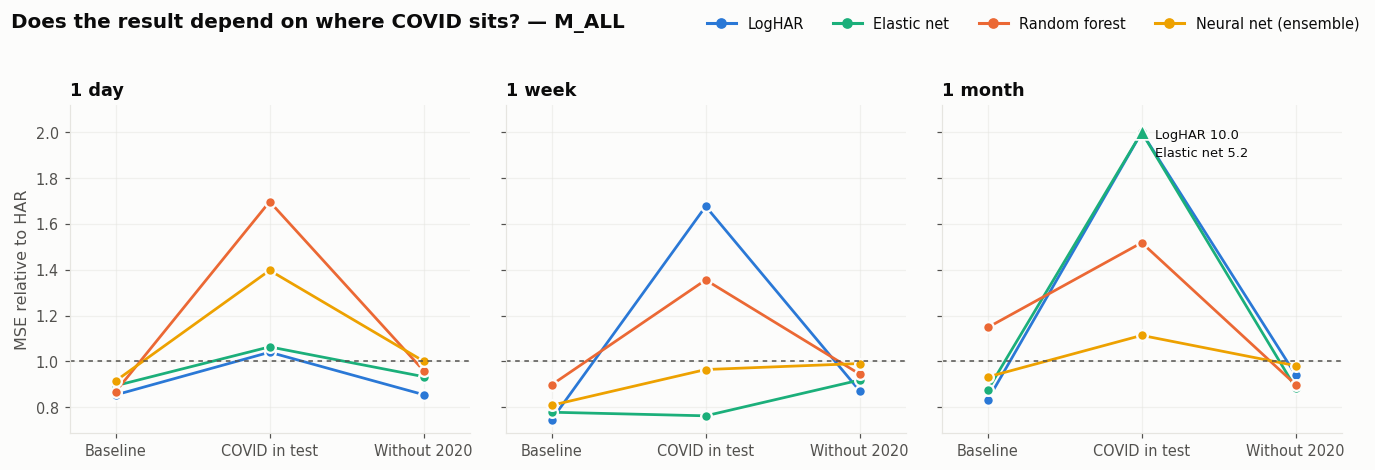

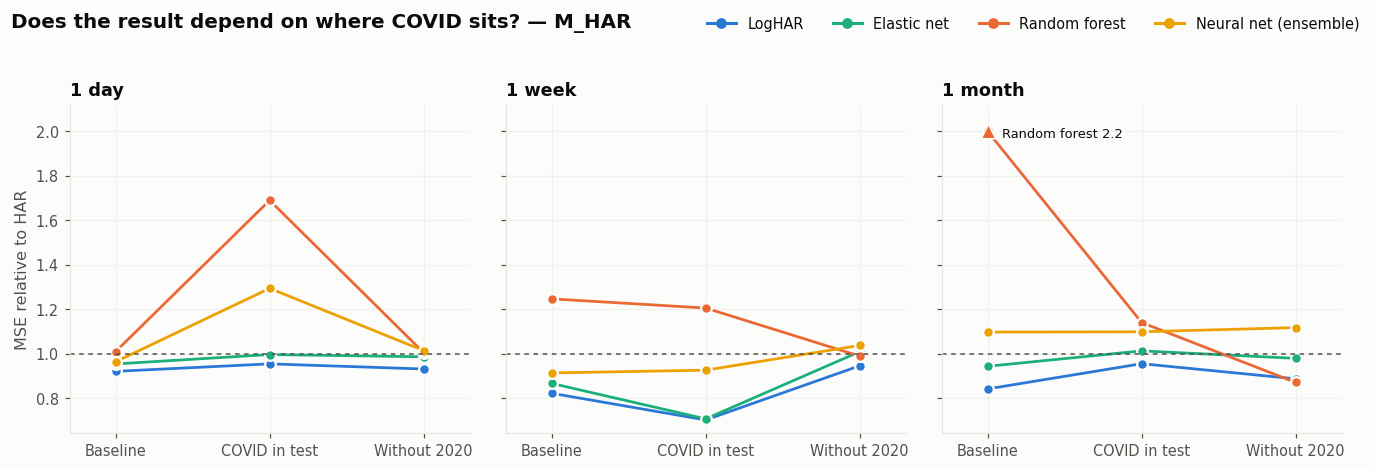

In [14]:
labels = {n: SCENARIOS[n]["label"] for n in RESULTS}
RESULTS_F = {n: V.insanity_filter(r, panel) for n, r in RESULTS.items()}
def scen_table(res):
    out = {}
    for ds in cfg.datasets:
        for h in cfg.horizons:
            for n, r in res.items():
                out[(ds, f"h={h}", labels[n])] = V.vs_benchmark(r, ds, h)["txt"]
    out = pd.DataFrame(out).reindex(P.ORDER).fillna("")
    out.index = [P.NAME[m] for m in out.index]
    return out
scen = scen_table(RESULTS_F)
TABLES["T7_scenarios"] = scen
TABLES["T7b_scenarios_unfiltered"] = scen_table(RESULTS)
print("Filtered (used for slides):"); display(scen)
print("Unfiltered:"); display(TABLES["T7b_scenarios_unfiltered"])
named = {labels[n]: r for n, r in RESULTS_F.items()}
P.fig_scenarios(named, "M_ALL", save=f"{FIG}/11_scenarios_M_ALL.png"); plt.show()
P.fig_scenarios(named, "M_HAR", save=f"{FIG}/12_scenarios_M_HAR.png"); plt.show()

In [15]:
# how concentrated is the HAR's error in each scenario? (COVID window and tariff shock)
rows = []
for n, r in RESULTS.items():
    for wname, w in (("COVID Feb-May 2020", EVENTS["COVID"]), ("Tariff shock Apr 2025", TARIFF)):
        share, frac = V.error_share(r, w, "M_HAR", 1)
        if frac > 0:
            rows.append({"scenario": labels[n], "window": wname, "share of HAR SSE": f"{share:.0%}",
                         "share of test days": f"{frac:.0%}"})
conc = pd.DataFrame(rows); TABLES["T8_error_concentration"] = conc; conc

,scenario,window,share of HAR SSE,share of test days
0,Baseline,Tariff shock Apr 2025,54%,4%
1,COVID in test,COVID Feb-May 2020,54%,4%
2,COVID in test,Tariff shock Apr 2025,12%,1%
3,Without 2020,Tariff shock Apr 2025,56%,4%


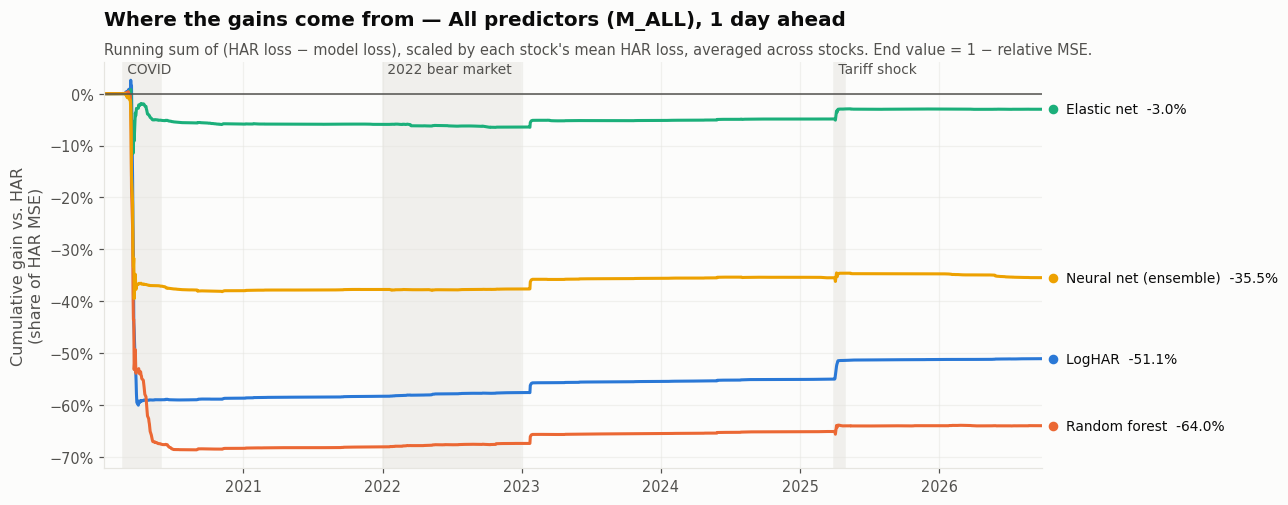

In [16]:
if "covid_test" in RESULTS:
    P.fig_cumgain(RESULTS["covid_test"], "M_ALL", 1, events=EVENTS,
                  save=f"{FIG}/13_cumulative_gain_covid_test_h1.png"); plt.show()

### Why the linear models suffer: COVID flips the HAR coefficients

OLS in levels minimizes squared errors, so the ~70 COVID days dominate the fit. We estimate HAR and HAR-X on the baseline in-sample window with and without 2020.

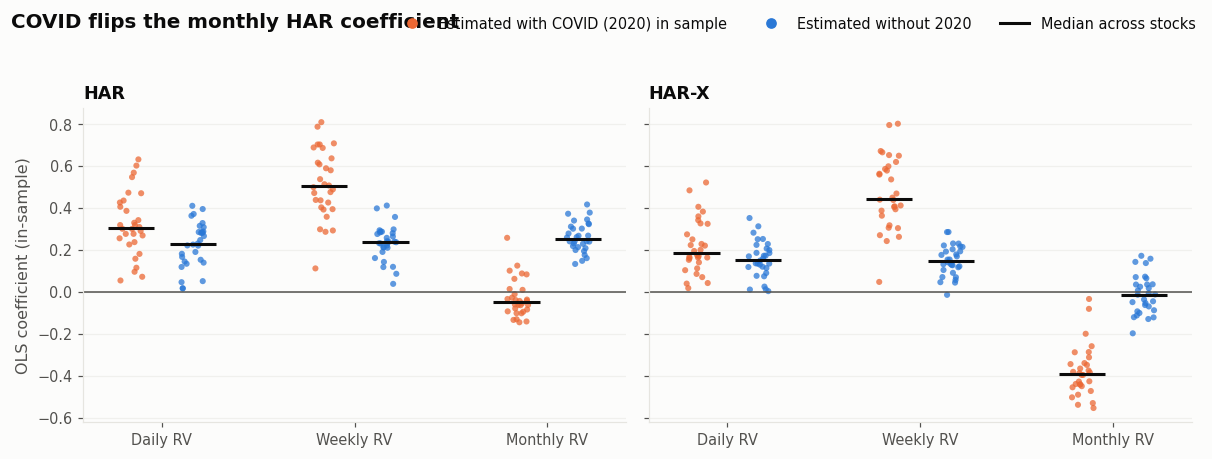

RVD_median  RVW_median  RVM_median  share_RVM_negative
model sample                                                              
HAR   with COVID         0.305       0.503      -0.049               0.733
      without 2020       0.228       0.238       0.251               0.000
HAR-X with COVID         0.185       0.444      -0.392               1.000
      without 2020       0.154       0.147      -0.013               0.567

In [17]:
_, d_va_base = V.split_dates(panel, scenario_cfg("baseline"))
coef = pd.concat([
    V.linear_coefficients(panel, macro, cfg, d_va_base, iv=iv).assign(sample="with COVID"),
    V.linear_coefficients(panel, macro, cfg, d_va_base, exclude=SCENARIOS["ex2020"]["train_exclude"], iv=iv).assign(sample="without 2020"),
])
P.fig_coefficients(coef, save=f"{FIG}/14_har_coefficients_covid.png"); plt.show()
coef_tab = coef.groupby(["model", "sample"]).agg(
    RVD_median=("RVD", "median"), RVW_median=("RVW", "median"), RVM_median=("RVM", "median"),
    share_RVM_negative=("RVM", lambda x: (x < 0).mean())).round(3)
TABLES["T9_har_coefficients"] = coef_tab
coef_tab

### Key numbers (computed, for the speaker notes)

In [18]:
def line(n, ds, h, m):
    r = V.vs_benchmark(RESULTS[n], ds, h).loc[m]
    return f"{P.NAME[m]:22s} rel. MSE {r['rel']:.3f}{r['stars']:3s}  beats HAR for {r['win']:.0%} of stocks"
for n in RESULTS:
    print(f"\n=== {labels[n]} ===")
    for ds in cfg.datasets:
        for h in cfg.horizons:
            best = V.rel_mse(RESULTS[n], ds, h).idxmin()
            print(f"{ds} h={h:2d}: best = {line(n, ds, h, best)}")


=== Baseline ===
M_HAR h= 1: best = LogHAR                 rel. MSE 0.921     beats HAR for 97% of stocks
M_HAR h= 5: best = LogHAR                 rel. MSE 0.823*    beats HAR for 97% of stocks
M_HAR h=22: best = LogHAR                 rel. MSE 0.842*    beats HAR for 93% of stocks
M_ALL h= 1: best = LogHAR                 rel. MSE 0.854**   beats HAR for 97% of stocks
M_ALL h= 5: best = LogHAR                 rel. MSE 0.746*    beats HAR for 100% of stocks
M_ALL h=22: best = LogHAR                 rel. MSE 0.832     beats HAR for 90% of stocks

=== COVID in test ===
M_HAR h= 1: best = LogHAR                 rel. MSE 0.927     beats HAR for 73% of stocks
M_HAR h= 5: best = LogHAR                 rel. MSE 0.635     beats HAR for 100% of stocks
M_HAR h=22: best = LogHAR                 rel. MSE 0.956     beats HAR for 53% of stocks
M_ALL h= 1: best = HAR-X                  rel. MSE 0.976     beats HAR for 70% of stocks
M_ALL h= 5: best = Ridge                  rel. MSE 0.688     beats 

## 6. Opening the black box: variable importance and ALE (baseline, paper Figures 6–7)

Models fitted on the initial training sample ($\mathcal M_{ALL}$, h = 1). Importance = standard deviation of the centered accumulated local effect, normalized to sum to one, averaged across stocks.

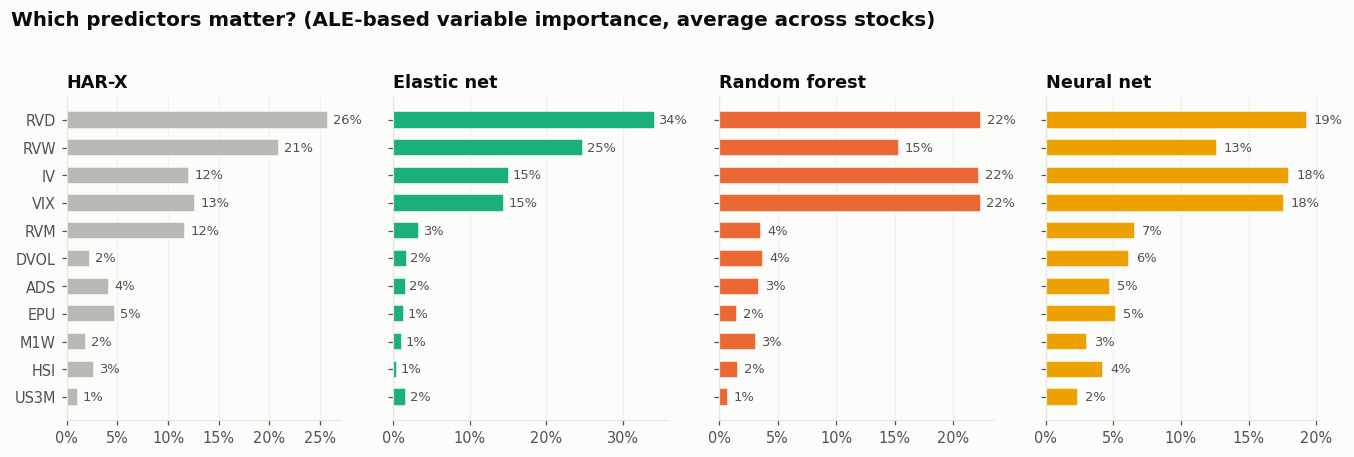

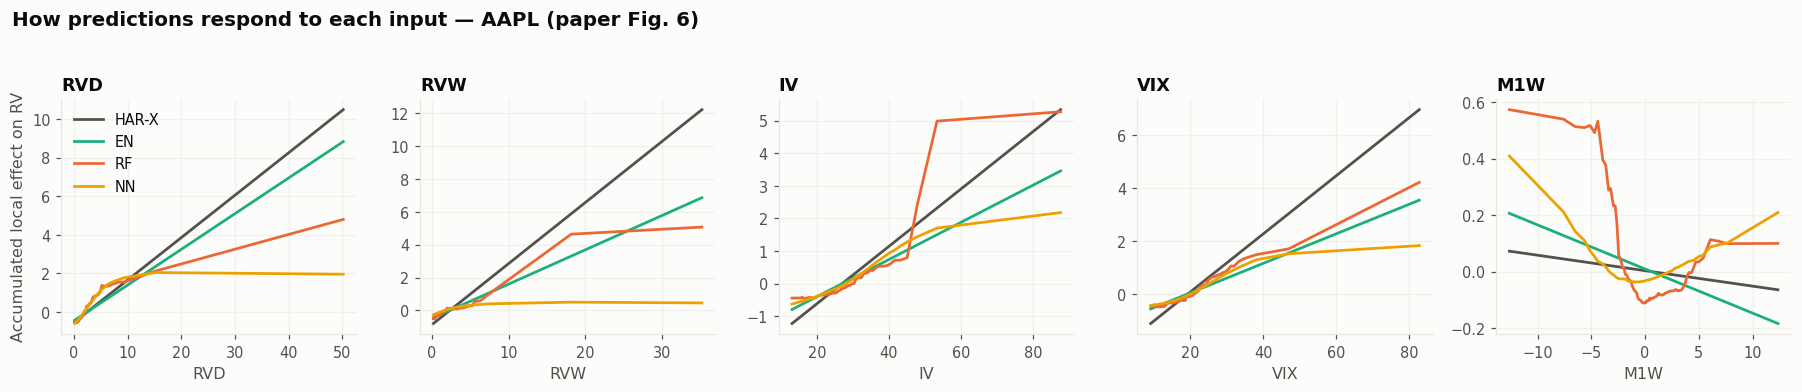

,HAR-X,EN,RF,NN
ADS,0.042,0.016,0.034,0.047
DVOL,0.023,0.018,0.038,0.062
EPU,0.048,0.014,0.015,0.052
HSI,0.026,0.005,0.016,0.043
IV,0.121,0.151,0.222,0.180
M1W,0.019,0.011,0.031,0.031
RVD,0.258,0.342,0.224,0.193
RVM,0.117,0.034,0.036,0.066
RVW,0.209,0.248,0.153,0.126
US3M,0.011,0.017,0.007,0.024


In [19]:
c_base = scenario_cfg("baseline")
d_tr, d_va = V.split_dates(panel, c_base)
vis, fitted0, tr0, sym0 = [], None, None, None
for s in cfg.symbols[:8]:
    if s not in set(panel.symbol):
        continue
    vi, fitted, tr = V.vi_for_stock(panel[panel.symbol == s], macro, c_base, d_tr, d_va,
                                    ea=None if ea is None else ea[ea.symbol == s],
                                    iv=None if iv is None else iv[iv.symbol == s])
    vis.append(vi)
    if fitted0 is None:
        fitted0, tr0, sym0 = fitted, tr, s
VI = pd.concat(vis).groupby(level=0).mean()
TABLES["T10_variable_importance"] = VI.round(3)
P.fig_vi(VI, save=f"{FIG}/15_variable_importance.png"); plt.show()
cols = [c for c in ["RVD", "RVW", "IV", "VIX", "M1W"] if c in tr0]
P.fig_ale(fitted0, tr0, cols, sym0, save=f"{FIG}/16_ale_{sym0}.png"); plt.show()
VI.round(3)

## 7. Robustness: data source (VOLARE vs. Alpaca 5-minute bars)

Runs automatically if a baseline run on the other source exists (e.g. `results/alpaca_full_iv/baseline/preds.pkl`; run the notebook once with `DATA_SOURCE = "alpaca"`).

In [20]:
other = "alpaca" if DATA_SOURCE == "volare" else "volare"
alt = os.path.join("results", TAG.replace(DATA_SOURCE, other, 1), "baseline", "preds.pkl")
if os.path.exists(alt):
    preds_alt, _ = pd.read_pickle(alt)
    src = pd.DataFrame({(f"h={h}", s): V.rel_mse(p, "M_ALL", h).round(3)
                        for h in cfg.horizons for s, p in ((DATA_SOURCE, preds), (other, preds_alt))})
    src = src.reindex(P.ORDER); TABLES["T11_data_source"] = src; display(src)
else:
    print("no run on", other, "found at", alt)

no run on alpaca found at results\alpaca_full_iv\baseline\preds.pkl


## 8. Export

In [21]:
xlsx = os.path.join(OUT, "slides_tables.xlsx")
with pd.ExcelWriter(xlsx) as w:
    for name, t in TABLES.items():
        t.to_excel(w, sheet_name=name[:31])
print("tables ->", xlsx)
print("figures ->", FIG); print("\n".join(sorted(os.listdir(FIG))))

tables -> results\volare_full_iv\slides_tables.xlsx
figures -> results\volare_full_iv\slides
01_rv_timeline_splits.png
02_heatmap_vs_paper_M_ALL.png
02_splits.png
03_heatmap_vs_paper_M_HAR.png
04_dumbbell_vs_paper_M_ALL.png
05_winrate_M_ALL.png
06_cumulative_gain_M_ALL_h1.png
07_cumulative_gain_M_ALL_h22.png
08_forecast_zoom_tariff.png
09_deciles_M_ALL_h1.png
10_boxplot_M_ALL_h1.png
11_scenarios_M_ALL.png
12_scenarios_M_HAR.png
13_cumulative_gain_covid_test_h1.png
14_har_coefficients_covid.png
15_variable_importance.png
16_ale_AAPL.png


## 9. Deviations from the original paper

| Paper | This replication | Why |
|---|---|---|
| NYSE TAQ, 29 DJIA stocks, 2001–2017 | VOLARE 5-min RV (cleaned tick data), Dow 30, 2016–2026 | TAQ not available; VOLARE is open and uses the same 5-min RV estimator |
| Model-free IV (OptionMetrics) | 30-day ATM implied vol (LSEG Workspace), call/put average | OptionMetrics not available |
| Earnings announcement dummy | omitted | no clean open source for 2016–2026 |
| One split (70/10/20) + 1,000/2,000-day robustness | three splits: baseline, COVID in test, without 2020 | the COVID year dominates OLS in levels |
| Tuning / trees re-estimated daily | OLS daily; regularization every 22 days, trees every 63 days | compute budget |
| NN: Leaky ReLU, dropout, best 10 of 100 nets | ReLU, L2 + early stopping, best 5 of 10 nets | paper fn. 7: ReLU no material difference |
| Adaptive/post lasso, bagging, MCS, VaR | not run | scope |

Added: QLIKE loss, win rates, error-concentration analysis, cumulative loss differentials, data-source robustness (Alpaca).